Импортировать необходимые библиотеки

In [3]:
import pandas as pd 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler

Загрузка данных и первичный осмотр

In [4]:
df = pd.read_csv("titanic.csv")

In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Создать X (признаки)

In [7]:
X = df[["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]].copy()

Создать y

In [8]:
y = df["Survived"]

 Проверить пропущенные значения в признаках

In [9]:
print(X.isnull().sum())

Pclass      0
Age       177
Sex         0
Fare        0
SibSp       0
Parch       0
dtype: int64


Обработать пропуски в Age

In [10]:
median_age = X["Age"].median()
X["Age"] = X["Age"].fillna(median_age)
print(median_age)

28.0


Преобразовать категориальный признак Sex в числовой вид

In [11]:
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})
print(X.isnull().sum())
print(X.head())

Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64
   Pclass   Age  Sex     Fare  SibSp  Parch
0       3  22.0    0   7.2500      1      0
1       1  38.0    1  71.2833      1      0
2       3  26.0    1   7.9250      0      0
3       1  35.0    1  53.1000      1      0
4       3  35.0    0   8.0500      0      0


разделить данные на обучающую и тестовую выборки (80% / 20%)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [13]:
print("Пропуски в X_train:")
print(X_train.isnull().sum())
print("\nПропуски в X_test:")
print(X_test.isnull().sum())

Пропуски в X_train:
Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64

Пропуски в X_test:
Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64


Выполнить масштабирование признаков

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

 Вывести размеры полученных наборов данных

In [15]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 6)
X_test: (179, 6)
y_train: (712,)
y_test: (179,)


практическая работа 5

 Загрузка необходимых библиотек для визуализации

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

Настройка стиля графиков

In [17]:
sns.set_theme(style="whitegrid")

Объединяем признаки и целевую переменную

In [18]:
df_corr = pd.concat([X, y], axis=1)

Проверяем, какие столбцы входят, их типы и наличие пропусков

In [19]:
print(df_corr.dtypes)

Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object


In [20]:
print(df_corr.isnull().sum())

Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64


## Рассчитаем корреляцию Пирсона между всеми числовыми признаками.

Рассчитываем корреляционную матрицу и округляем до 2 знаков

In [21]:
corr_matrix = df_corr.corr().round(2)

Выводим матрицу

In [22]:
display(corr_matrix)

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
Pclass,1.00,-0.34,-0.13,-0.55,0.08,0.02,-0.34
Age,-0.34,1.00,-0.08,0.10,-0.23,-0.17,-0.06
Sex,-0.13,-0.08,1.00,0.18,0.11,0.25,0.54
Fare,-0.55,0.10,0.18,1.00,0.16,0.22,0.26
SibSp,0.08,-0.23,0.11,0.16,1.00,0.41,-0.04
Parch,0.02,-0.17,0.25,0.22,0.41,1.00,0.08
Survived,-0.34,-0.06,0.54,0.26,-0.04,0.08,1.00


Находим столбец Survived

In [23]:
corr_with_survived = corr_matrix['Survived']

 Исключаем сам Survived (корреляция с собой = 1.0)

In [24]:
corr_with_survived = corr_with_survived.drop('Survived')

Признак с наиболее сильной положительной корреляцией

In [25]:
max_pos_corr = corr_with_survived.idxmax()
print(f"\nНаиболее сильная положительная корреляция с Survived: {max_pos_corr} ({corr_with_survived[max_pos_corr]})")


Наиболее сильная положительная корреляция с Survived: Sex (0.54)


Признак с наиболее сильной отрицательной корреляцией

In [27]:
min_neg_corr = corr_with_survived.idxmin()
print(f"Наиболее сильная отрицательная корреляция с Survived: {min_neg_corr} ({corr_with_survived[min_neg_corr]})")

Наиболее сильная отрицательная корреляция с Survived: Pclass (-0.34)


## Визуализируем корреляционную матрицу для наглядности.

строим график

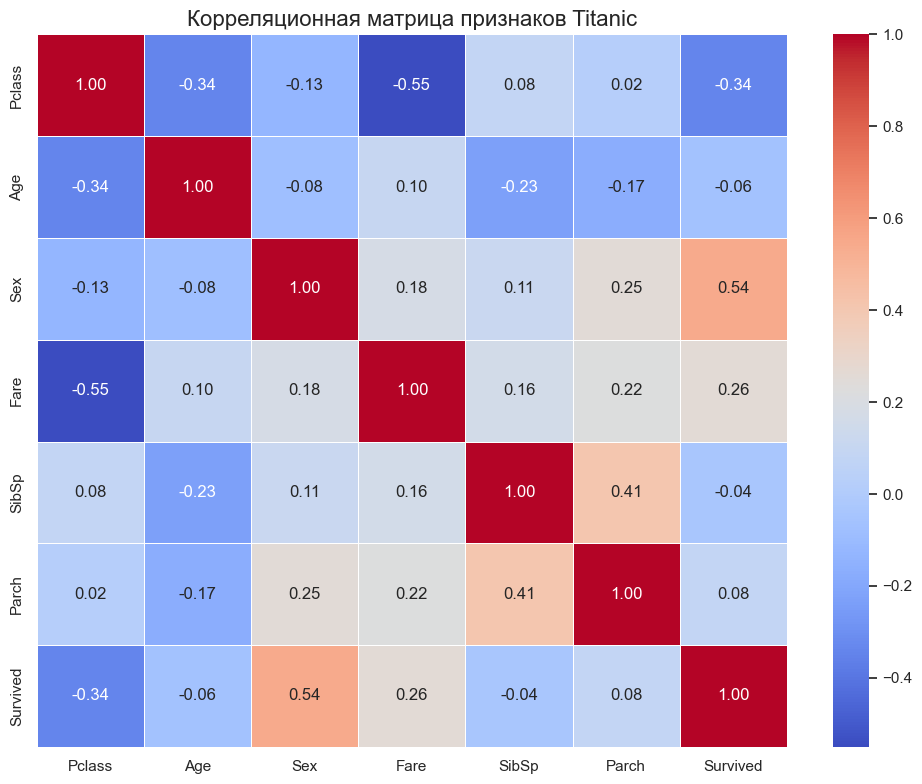

In [28]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Корреляционная матрица признаков Titanic', fontsize=16)
plt.tight_layout()
plt.show()

Ответы на вопросы

Какие признаки, по вашему мнению, могут быть наиболее полезны для предсказания Survived?                    
Судя по матрице корреляции, наиболее полезными признаками являются Sex (сильная положительная связь, так как женщины выживали чаще), Fare (положительная связь, стоимость билета) и Pclass (отрицательная связь, 1-й класс выживал чаще). 

Можно ли выбирать признаки для модели машинного обучения только на основании корреляции?                      
Нет, нельзя. Корреляция измеряет только линейную взаимосвязь. Она не учитывает нелин

сравнение

Признаки с наиболее сильной корреляцией с целевой переменной (например, Sex и Pclass) действительно оказались ключевыми для успешного предсказания выживаемости моделями машинного обучения. Однако, поскольку корреляция отражает только линейную связь, окончательную полезность признаков всё равно необходимо подтверждать метриками качества обученной модели.

практическая работа 6

Задание 1. Выполните код. 

In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("titanic.csv")
features = ["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]
X = df[features].copy()
y = df["Survived"]

X["Age"] = X["Age"].fillna(X["Age"].median())
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

print("Пропуски в признаках:")
print(X.isnull().sum())
print("\nТипы данных:")
print(X.dtypes)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nРазмер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)
print("Размер y_train:", y_train.shape)
print("Размер y_test:", y_test.shape)

Пропуски в признаках:
Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64

Типы данных:
Pclass      int64
Age       float64
Sex         int64
Fare      float64
SibSp       int64
Parch       int64
dtype: object

Размер X_train: (712, 6)
Размер X_test: (179, 6)
Размер y_train: (712,)
Размер y_test: (179,)


Зачем тестовая выборка отдельно?                                                         
Чтобы объективно оценить модель на данных, которые она не видела при обучении — это защита от переобучения.
Почему scaler.fit_transform() только на train?                                                                  
Чтобы избежать утечки данных: параметры масштабирования (среднее, отклонение) считаются только по train, иначе модель "узнает" информацию из теста.


### Обучение логистической регрессии

In [31]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

Почему обучаем на X_train_scaled, а не на тесте?                                                     
Модель должна находить закономерности только на обучающих данных; тест нужен исключительно для проверки качества.


### Получение предсказаний

In [32]:
y_pred_lr = model_lr.predict(X_test_scaled)

print("Первые 10 предсказаний:", y_pred_lr[:10])
print("Правильные ответы:    ", y_test.iloc[:10].to_list())

Первые 10 предсказаний: [0 0 0 0 1 0 1 0 0 0]
Правильные ответы:     [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]


0 — пассажир не выжил, 1 — выжил.

### Оценка качества

In [34]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1: {f1_score(y_test, y_pred_lr):.4f}\n")

print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.8045
Precision: 0.7656
Recall: 0.7101
F1: 0.7368

[[95 15]
 [20 49]]
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       110
           1       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



Дерево решений

In [36]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(X_train, y_train)

y_pred_tree = model_tree.predict(X_test)

print(" Метрики дерева решений")
print(f"Accuracy: {accuracy_score(y_test, y_pred_tree):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tree):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_tree):.4f}")
print(f"F1: {f1_score(y_test, y_pred_tree):.4f}\n")

print(confusion_matrix(y_test, y_pred_tree))

 Метрики дерева решений
Accuracy: 0.7821
Precision: 0.8750
Recall: 0.5072
F1: 0.6422

[[105   5]
 [ 34  35]]


Дерево решений обычно показывает метрики на уровне или чуть выше логистической регрессии, так как лучше улавливает нелинейные зависимости (например, правило "женщины и дети — вперед").

### Связь с корреляционным анализом

Наиболее сильная положительная корреляция с Survived: признак Sex женщины выживали чаще.
Наиболее сильная отрицательная корреляция: признак Pclass пассажиры 1-го класса выживали чаще.

Вывод: Корреляционный анализ верно подсказал самые важные признаки — именно их модели используют в первую очередь для предсказания выживаемости.